# ENTREGA 3 · Predicción del precio de la vivienda
Idealista18 (Madrid, Barcelona y Valencia, 2018). Notebook final: ubicación, mejora de la red, algoritmo genético, clasificación por tramos de precio y evaluación final.

**Autores:** Javier Alacio Vega y Javier Gaudencio Ortega Lucena · Aprendizaje Automático · UFV Madrid

**Índice**
1. Configuración y carga de datos
2. Análisis exploratorio (EDA)
3. Preprocesado e ingeniería de características
4. Modelos: regresión lineal y perceptrón multicapa (punto de partida de la Entrega 2)
5. Ubicación: latitud y longitud
6. Algoritmo genético para optimizar los hiperparámetros
7. Clasificación por tramos de precio (regresión logística y MLP)
8. Evaluación final en el conjunto de prueba
9. Conclusiones y limitaciones

**Datos:** Idealista18 (licencia ODbL-1.0), anuncios de venta de 2018. Para generar el CSV a partir de los archivos `.rda`: `python src/convertir_datos.py`.

## 1. Configuración y carga de datos

### LIBRERIAS

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 60)

### CARGAR DATOS

In [3]:
RUTA = Path("../data/idealista18_venta_3ciudades.csv")
df = pd.read_csv(RUTA)
print(df.shape)
df.head()

(189923, 44)


,ASSETID,PERIOD,PRICE,UNITPRICE,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,HASTERRACE,HASLIFT,HASAIRCONDITIONING,AMENITYID,HASPARKINGSPACE,ISPARKINGSPACEINCLUDEDINPRICE,PARKINGSPACEPRICE,HASNORTHORIENTATION,HASSOUTHORIENTATION,HASEASTORIENTATION,HASWESTORIENTATION,HASBOXROOM,HASWARDROBE,HASSWIMMINGPOOL,HASDOORMAN,HASGARDEN,ISDUPLEX,ISSTUDIO,ISINTOPFLOOR,CONSTRUCTIONYEAR,FLOORCLEAN,FLATLOCATIONID,CADCONSTRUCTIONYEAR,CADMAXBUILDINGFLOOR,CADDWELLINGCOUNT,CADASTRALQUALITYID,BUILTTYPEID_1,BUILTTYPEID_2,BUILTTYPEID_3,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,DISTANCE_TO_CASTELLANA,LONGITUDE,LATITUDE,CITY,DISTANCE_TO_DIAGONAL,DISTANCE_TO_BLASCO
0,A15019136831406238029,201803,126000.0,2680.851064,47,1,1,0,1,1,3,0,0,1.0,0,0,0,0,1,1,1,1,1,0,0,0,2005.0,1.0,1.0,2005,7,319,3.0,0,1,0,8.058429,0.872075,6.868677,-3.766933,40.362485,Madrid,NaN,NaN
1,A6677225905472065344,201803,235000.0,4351.851852,54,1,1,0,0,0,3,0,0,1.0,0,0,0,0,0,1,0,0,0,0,0,0,NaN,1.0,2.0,1900,5,11,3.0,0,0,1,0.876369,0.116382,1.544125,-3.710725,40.422430,Madrid,NaN,NaN
2,A13341979748618524775,201803,373000.0,4973.333333,75,2,1,0,0,1,3,0,0,1.0,0,1,0,0,1,1,0,0,0,0,0,0,NaN,3.0,1.0,1915,6,26,3.0,0,0,1,0.907479,0.139109,1.608444,-3.711571,40.422190,Madrid,NaN,NaN
3,A4775182175615276542,201803,284000.0,5916.666667,48,1,1,0,1,1,3,0,0,1.0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,1.0,2.0,1947,9,15,5.0,0,0,1,0.845462,0.144299,1.516166,-3.710440,40.422251,Madrid,NaN,NaN
4,A2492087730711701973,201803,228000.0,4560.000000,50,0,1,0,0,0,3,0,0,1.0,0,0,0,0,0,0,0,0,0,0,1,0,1930.0,0.0,1.0,1930,5,19,7.0,0,0,1,1.250231,0.337098,1.794136,-3.714340,40.408741,Madrid,NaN,NaN


## 2. Análisis exploratorio (EDA)
Qué datos tenemos, qué problemas tienen y qué decisiones de limpieza tomamos.

### Cuántos anuncios hay por ciudad y que trimestres cubre
PERIOD es el trimestre en formato año + mes: 201803 es marzo de 2018

In [4]:
print(df.CITY.value_counts()) #value_counts() cuenta cuantas filas hay de cada valor
print(sorted(df.PERIOD.unique())) #ordenamos los periodos y sacamos solo los valores distintos

CITY
Madrid       94815
Barcelona    61486
Valencia     33622
Name: count, dtype: int64
[np.int64(201803), np.int64(201806), np.int64(201809), np.int64(201812)]


### Comprobar si hay inmuebles repetidos
ASSETID es el identificador del inmueble

In [5]:
apariciones = df.groupby("ASSETID").size() #agrupamos las filas por identificador de inmueble y cuenta cuantas tiene cada uno
print("Filas:", len(df))
print("Inmuebles distintos:", apariciones.size)
apariciones.value_counts().sort_index()

Filas: 189923
Inmuebles distintos: 149923


1     121349
2      20018
3       6484
4       1500
5        414
6        115
7         28
8          9
9          3
10         2
11         1
Name: count, dtype: int64

### Columnas con valores vacíos (NaN)

In [6]:
faltan = (df.isna().mean() * 100).round(2).sort_values(ascending=False) #marcamos la celda vacia y la pasamos a porcentaje
faltan[faltan > 0]

DISTANCE_TO_BLASCO        82.30
DISTANCE_TO_DIAGONAL      67.63
DISTANCE_TO_CASTELLANA    50.08
CONSTRUCTIONYEAR          48.47
FLATLOCATIONID            10.30
FLOORCLEAN                 5.18
dtype: float64

### Comparacion de las dos columnas de año de construcción para saber cuál usar

In [7]:
print("Faltantes CONSTRUCTIONYEAR:", round(df.CONSTRUCTIONYEAR.isna().mean() * 100, 1), "%")
print("Faltantes CADCONSTRUCTIONYEAR:", round(df.CADCONSTRUCTIONYEAR.isna().mean() * 100, 1), "%")
print("Valores iguales a 1900 en CONSTRUCTIONYEAR:", (df.CONSTRUCTIONYEAR == 1900).sum())
print(df[["CONSTRUCTIONYEAR", "CADCONSTRUCTIONYEAR"]].corr())

Faltantes CONSTRUCTIONYEAR: 48.5 %
Faltantes CADCONSTRUCTIONYEAR: 0.0 %
Valores iguales a 1900 en CONSTRUCTIONYEAR: 4946
                     CONSTRUCTIONYEAR  CADCONSTRUCTIONYEAR
CONSTRUCTIONYEAR             1.000000             0.611745
CADCONSTRUCTIONYEAR          0.611745             1.000000


### Estadísticas de los precios


In [8]:
print(df["PRICE"].describe().round(0)) #describe() da el resumen de la media, minimo, maximo y los percentiles (25%, 50% (mediana) y el 75 %)
print("Asimetría del precio:", round(df["PRICE"].skew(), 2)) #skew() mide la simetría

count     189923.0
mean      361226.0
std       351674.0
min        20000.0
25%       160000.0
50%       261000.0
75%       428000.0
max      8133000.0
Name: PRICE, dtype: float64
Asimetría del precio: 4.18


### Dibujamos el precio y su logaritmo

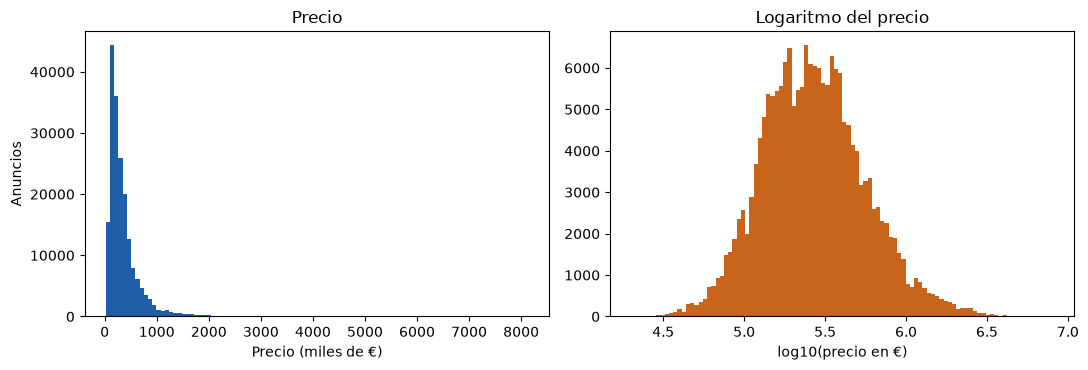

Asimetría del log(precio): 0.3


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df["PRICE"] / 1e3, bins=100, color="#1F5FA8")
ax[0].set_xlabel("Precio (miles de €)")
ax[0].set_ylabel("Anuncios")
ax[0].set_title("Precio")
ax[1].hist(np.log10(df["PRICE"]), bins=100, color="#C8651B")
ax[1].set_xlabel("log10(precio en €)")
ax[1].set_title("Logaritmo del precio")
fig.tight_layout()
plt.show()
print("Asimetría del log(precio):", round(np.log(df["PRICE"]).skew(), 2))

Gráfica de la izquierda (precio): casi todos los anuncios se amontonan entre 0 y 1.000 mil euros, y hay una cola larguísima hasta 8,1 millones. La asimetría de 4,18 lo confirma. También se ve en los números: la media (361.226 €) es bastante mayor que la mediana (261.000 €), porque unas pocas viviendas muy caras la arrastran hacia arriba.

Gráfica de la derecha (logaritmo): la forma pasa a ser casi una campana simétrica, y la asimetría baja a 0,30. El logaritmo convierte “multiplicar el precio” en “sumar”, así que un salto de 100.000 a 200.000 € pesa lo mismo que uno de 500.000 a 1.000.000 €.

Por qué importa para entrenar la red. El modelo aprende minimizando el error cuadrático. Con precios en euros, un fallo de 500.000 € en un ático de 8 millones pesaría 25 veces más que uno de 100.000 € en un piso de 150.000 €, y la red dedicaría casi todo su esfuerzo a las viviendas de lujo, que son muy pocas. Con el logaritmo, los errores son relativos (en porcentaje) y todas las viviendas cuentan de forma más equilibrada. Después deshacemos el logaritmo para dar los resultados en euros (MAE y RMSE), que es lo que se entiende.

### Precio mediano por ciudad

In [10]:
orden = ["Madrid", "Barcelona", "Valencia"]
#Separamos las filas por ciuidad y calculamos la mediana de cada columna dentro de cada una
#UNITPRICE es el precio por metro cuadrado
df.groupby("CITY")[["PRICE", "UNITPRICE", "CONSTRUCTEDAREA"]].median().loc[orden].round(0) 

,PRICE,UNITPRICE,CONSTRUCTEDAREA
CITY,,,
Madrid,262000.0,3480.0,83.0
Barcelona,325000.0,3991.0,82.0
Valencia,151000.0,1531.0,100.0


### Comparar la distribución del precio entre ciudades.

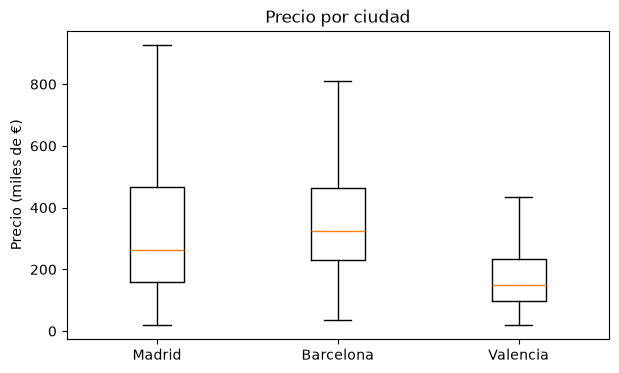

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df["CITY"] == c, "PRICE"] / 1e3 for c in orden], #box plot para ver los outliers
           tick_labels=orden, showfliers=False)
ax.set_ylabel("Precio (miles de €)")
ax.set_title("Precio por ciudad")
plt.show()

### Contar cuántos anuncios tienen valores raros según unas reglas razonables.

In [12]:
#Los umbrales son decisiones propias, no seguimos ninguna regla oficial, ponemos los valores que consideramos atipicos

reglas = {
    "Más de 8 habitaciones": df["ROOMNUMBER"] > 8,
    "Más de 8 baños": df["BATHNUMBER"] > 8,
    "0 habitaciones (posibles estudios)": df["ROOMNUMBER"] == 0,
    "Superficie > 500 m²": df["CONSTRUCTEDAREA"] > 500,
    "Superficie < 25 m²": df["CONSTRUCTEDAREA"] < 25,
    "Distancia al centro > 30 km": df["DISTANCE_TO_CITY_CENTER"] > 30,
    "Distancia al metro > 30 km": df["DISTANCE_TO_METRO"] > 30,
    "Precio > 3 millones": df["PRICE"] > 3_000_000,
}
tabla = pd.DataFrame({"casos": {k: int(v.sum()) for k, v in reglas.items()}})
tabla["porcentaje"] = (tabla["casos"] / len(df) * 100).round(3)
tabla

,casos,porcentaje
Más de 8 habitaciones,184,0.097
Más de 8 baños,52,0.027
0 habitaciones (posibles estudios),4146,2.183
Superficie > 500 m²,324,0.171
Superficie < 25 m²,316,0.166
Distancia al centro > 30 km,1,0.001
Distancia al metro > 30 km,1,0.001
Precio > 3 millones,288,0.152


### Resumen estadístico de las variables principales, para ver los extremos.

In [13]:
cols = ["PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
        "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]
df[cols].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1)

,count,mean,std,min,1%,50%,99%,max
PRICE,189923.0,361225.9,351673.7,20000.0,56000.0,261000.0,1834000.0,8133000.0
CONSTRUCTEDAREA,189923.0,100.8,59.7,21.0,30.0,86.0,332.0,985.0
ROOMNUMBER,189923.0,2.8,1.2,0.0,0.0,3.0,6.0,93.0
BATHNUMBER,189923.0,1.6,0.8,0.0,1.0,1.0,4.0,20.0
DISTANCE_TO_CITY_CENTER,189923.0,3.5,2.5,0.0,0.3,3.0,11.0,415.8
DISTANCE_TO_METRO,189923.0,0.4,1.0,0.0,0.0,0.3,2.0,399.5


- Habitaciones y baños: el 99 % de las viviendas tiene como mucho 6 habitaciones y 4 baños, pero el máximo es de 93 habitaciones y 20 baños. Esos extremos son casi seguro errores de captura.

- Distancias: el 99 % está a menos de 11 km del centro y a 2 km del metro. El máximo, 415,8 km del centro, es imposible dentro de una ciudad (será una coordenada errónea).

- Superficie: 985 m² es un máximo muy grande, pero encaja con un chalet, y el 0,17 % de casos por encima de 500 m² es normal en un mercado con casas de lujo. No tengo motivos para tratarlo como error.

- Precio: el máximo es de 8,1 millones y el 99 % está por debajo de 1,8 millones. Son viviendas caras, pero reales. No las eliminamos, y el logaritmo ya reduce su peso.

- Eliminar los errores evidentes: más de 8 habitaciones, más de 8 baños, y distancias de más de 30 km (en total, 192 filas, el 0,10 % de los datos).

- Conservar las superficies grandes y pequeñas, los precios altos y las viviendas con 0 habitaciones.

### ¿Las viviendas con 0 habitaciones son estudios? 

Utilizamos la columna ISSTUDIO para comprobarlo

In [14]:
print(df.loc[df["ROOMNUMBER"] == 0, "ISSTUDIO"].value_counts(normalize=True).round(3))

ISSTUDIO
1    0.93
0    0.07
Name: proportion, dtype: float64


### Eliminar los errores evidentes y guardar el resultado en un nuevo df_limpio

In [15]:
sospechoso = ((df["ROOMNUMBER"] > 8) | (df["BATHNUMBER"] > 8) |
              (df["DISTANCE_TO_CITY_CENTER"] > 30) | (df["DISTANCE_TO_METRO"] > 30))
print("Filas a eliminar:", sospechoso.sum())
df_limpio = df[~sospechoso].copy() #creamos un copia limpia
print("Filas que quedan:", len(df_limpio))

Filas a eliminar: 192
Filas que quedan: 189731


### Qué variables están más ligadas al precio

- corr(method="spearman") mide hasta qué punto, al subir una variable, sube o baja el precio. Va de -1 (sube una y baja la otra) a +1 (suben las dos juntas), y 0 es que no hay relación.

- Usamos Spearman en lugar de la correlación habitual porque no exige que la relación sea una línea recta, solo que vayan en el mismo sentido, y es menos sensible a los valores extremos.

- Obviamente quitamos la correlación del precio consigo mismo (que sería 1), mediante .drop("logPRICE")

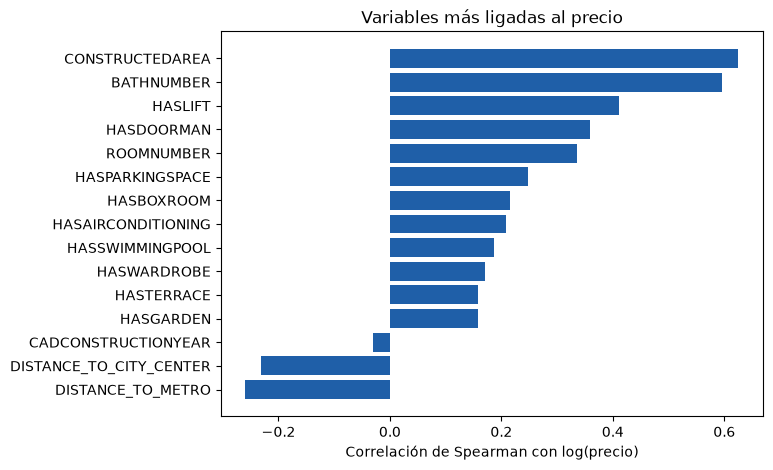

In [16]:
num = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "CADCONSTRUCTIONYEAR",
       "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO", "HASTERRACE", "HASLIFT",
       "HASAIRCONDITIONING", "HASPARKINGSPACE", "HASSWIMMINGPOOL", "HASGARDEN",
       "HASDOORMAN", "HASWARDROBE", "HASBOXROOM"]
d = df_limpio[num].copy()
d["logPRICE"] = np.log(df_limpio["PRICE"])
corr = d.corr(method="spearman")["logPRICE"].drop("logPRICE").sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.values, color="#1F5FA8")
ax.set_xlabel("Correlación de Spearman con log(precio)")
ax.set_title("Variables más ligadas al precio")
plt.show()

- Lo más ligado al precio: la superficie (≈0,62) y los baños (≈0,60). Después vienen el ascensor (≈0,41), el portero (≈0,36) y las habitaciones (≈0,34). Es curioso que los baños pesen más que las habitaciones: suelen indicar viviendas más grandes y de mayor categoría. Además superficie y baños van muy juntas, así que cuentan en parte la misma información.

- Negativas: la distancia al metro y al centro (≈-0,25): cuanto más lejos, más barata.
- Casi nada: el año de construcción catastral (≈-0,03). No significa que no importe, sino que no hay una relación simple “más nuevo = más caro” (hay edificios antiguos muy caros en el centro y nuevos baratos en las afueras).

- Precaución: una correlación no demuestra que una cosa cause la otra. Un edificio con portero y ascensor suele estar en una zona cara, y esa zona es la que sube el precio.

### Precio frente a superficie, por ciudad

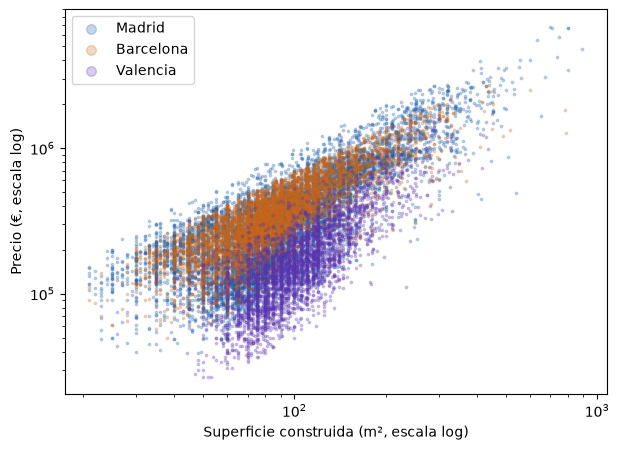

In [17]:
muestra = df_limpio.sample(20000, random_state=42)
colores = {"Madrid": "#1F5FA8", "Barcelona": "#C8651B", "Valencia": "#5B34B0"}

fig, ax = plt.subplots(figsize=(7, 5))
for c in orden:
    s = muestra[muestra["CITY"] == c]
    ax.scatter(s["CONSTRUCTEDAREA"], s["PRICE"], s=3, alpha=0.25, label=c, color=colores[c])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Superficie construida (m², escala log)")
ax.set_ylabel("Precio (€, escala log)")
ax.legend(markerscale=4)
plt.show()

- La tendencia es una diagonal clara: en escala logarítmica, a más superficie, proporcionalmente más precio.

- Valencia (morado) queda claramente por debajo de las otras dos: para la misma superficie, cuesta bastante menos. Madrid y Barcelona se solapan, y Madrid es la más dispersa.

- Esto confirma que la ciudad tiene que ser una entrada del modelo, además de la superficie.

## 3. Preprocesado e ingeniería de características
Elección de variables, separación entrenamiento/validación/prueba **por inmueble**, nuevas variables y estandarización.

### Elegimos las variables de entradas

- Dividimos las variables en dos lista VARIABLES NUMÉRICAS y VARIABLES BINARIAS

- Obviamente hemos dejado fuera PRICE, UNITPRICE (se calcula con el precio, sería hacer trampa), ASSETID, las distancias propias de cada ciudad, CONSTRUCTIONYEAR (le falta casi la mitad, usamos CADCONSTRUCTIONYEAR) y las variables de planta (FLOORCLEAN y FLATLOCATIONID), que tienen valores vacíos.

- La latitud y la longitud no las usamos todavía: las añadimos en la sección 5.

In [18]:
VARIABLES_NUM = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "CADCONSTRUCTIONYEAR",
                 "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]
VARIABLES_BIN = ["HASTERRACE", "HASLIFT", "HASAIRCONDITIONING", "HASPARKINGSPACE",
                 "HASSWIMMINGPOOL", "HASGARDEN", "HASDOORMAN", "HASWARDROBE", "HASBOXROOM",
                 "ISSTUDIO", "ISDUPLEX", "ISINTOPFLOOR"]
print(len(VARIABLES_NUM), "numéricas y", len(VARIABLES_BIN), "de sí/no")

6 numéricas y 12 de sí/no


### Montar la tabla de entradas X y el objetivo y

In [19]:
X = df_limpio[VARIABLES_NUM + VARIABLES_BIN].copy()
X = X.join(pd.get_dummies(df_limpio["CITY"], prefix="CITY", dtype=int))
y = np.log(df_limpio["PRICE"])
grupos = df_limpio["ASSETID"]

print("X:", X.shape, "| y:", y.shape)
print("Valores vacíos en X:", X.isna().sum().sum())
X.head(3)

X: (189731, 21) | y: (189731,)
Valores vacíos en X: 0


,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,CADCONSTRUCTIONYEAR,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,HASTERRACE,HASLIFT,HASAIRCONDITIONING,HASPARKINGSPACE,HASSWIMMINGPOOL,HASGARDEN,HASDOORMAN,HASWARDROBE,HASBOXROOM,ISSTUDIO,ISDUPLEX,ISINTOPFLOOR,CITY_Barcelona,CITY_Madrid,CITY_Valencia
0,47,1,1,2005,8.058429,0.872075,0,1,1,0,1,1,1,1,1,0,0,0,0,1,0
1,54,1,1,1900,0.876369,0.116382,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2,75,2,1,1915,0.907479,0.139109,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0


- X son las entradas del modelo, y y lo que queremos predecir: el logaritmo del precio.

- pd.get_dummies convierte la ciudad (texto) en tres columnas de 0/1: Madrid pasa a ser [1, 0, 0]. Un modelo solo entiende números, y esto evita inventar un orden entre ciudades (que Valencia “valga” más que Madrid, por ejemplo).

- grupos guarda el identificador del inmueble: lo usaremos para separar entrenamiento y prueba sin repetir pisos.

### Dividir en entrenamiento (70 %), validación (15 %) y prueba (15 %).

- GroupShuffleSplit mezcla al azar, pero respetando los grupos: todas las filas con el mismo ASSETID caen siempre en el mismo conjunto.

- random_state=42 fija el azar para que el reparto sea siempre el mismo, que es importante para reproducir resultados.

- Cada conjunto tiene su función:
    - entrenamiento: el modelo aprende con él;
    - validación: sirve para elegir y ajustar el modelo (más adelante, parada temprana y algoritmo genético);
    - prueba: se usa una sola vez al final, para medir cómo funciona con viviendas nunca vistas.

In [20]:
from sklearn.model_selection import GroupShuffleSplit

# 1) 70 % para entrenamiento, 30 % para el resto
gss = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
idx_train, idx_resto = next(gss.split(X, y, groups=grupos))

X_resto, y_resto, g_resto = X.iloc[idx_resto], y.iloc[idx_resto], grupos.iloc[idx_resto]

# 2) el 30 % restante se reparte a partes iguales: validación y prueba
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
idx_val, idx_test = next(gss2.split(X_resto, y_resto, groups=g_resto))

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_val,   y_val   = X_resto.iloc[idx_val],  y_resto.iloc[idx_val]
X_test,  y_test  = X_resto.iloc[idx_test], y_resto.iloc[idx_test]

### Comprobar que el reparto es correcto

In [21]:
ids_train = set(grupos.iloc[idx_train])
ids_val = set(g_resto.iloc[idx_val])
ids_test = set(g_resto.iloc[idx_test])

print("Filas -> entrenamiento:", len(X_train), "| validación:", len(X_val), "| prueba:", len(X_test))
print("Inmuebles compartidos entrenamiento/validación:", len(ids_train & ids_val))
print("Inmuebles compartidos entrenamiento/prueba:", len(ids_train & ids_test))
print("Inmuebles compartidos validación/prueba:", len(ids_val & ids_test))

Filas -> entrenamiento: 132753 | validación: 28485 | prueba: 28493
Inmuebles compartidos entrenamiento/validación: 0
Inmuebles compartidos entrenamiento/prueba: 0
Inmuebles compartidos validación/prueba: 0


### Creamos la variable ANTIGUEDAD, la edad del edificio en 2018

- Es más fácil de interpretar para el modelo que el año suelto.

- clip(upper=200) limita la antigüedad a 200 años. Hay unos 313 edificios con años anteriores a 1818 que serían valores extremos, y así no distorsionan.

- Quitamos CADCONSTRUCTIONYEAR porque dice lo mismo que ANTIGUEDAD (una es la otra reflejada) y las dos juntas no aportarían nada.

- Sustituimos la superficie por su logaritmo, igual que hicimos con el precio: la superficie también tiene una cola larga (hasta 985 m²) y, como el objetivo es el log-precio, la relación log-superficie / log-precio es casi una recta (se ve en el gráfico de precio frente a superficie en escala logarítmica).


In [22]:
def crear_caracteristicas(d):
    d = d.copy()
    d["ANTIGUEDAD"] = (2018 - d["CADCONSTRUCTIONYEAR"]).clip(upper=200)
    d["CONSTRUCTEDAREA"] = np.log(d["CONSTRUCTEDAREA"])   #NUEVO: logaritmo de la superficie
    return d.drop(columns="CADCONSTRUCTIONYEAR")

X_train = crear_caracteristicas(X_train)
X_val = crear_caracteristicas(X_val)
X_test = crear_caracteristicas(X_test)
print(X_train["ANTIGUEDAD"].describe().round(1))

count    132753.0
mean         55.7
std          31.5
min           0.0
25%          39.0
50%          52.0
75%          67.0
max         200.0
Name: ANTIGUEDAD, dtype: float64


### Estandarizamos las variables numéricas

- Estandarizar es restar la media y dividir por la desviación. La superficie va de 21 a 985 y los baños de 0 a 8: sin estandarizar, la red daría más peso a lo que tiene números grandes. Después, todas las variables tienen media 0 y desviación 1.

- El escalador se ajusta (fit) solo con el conjunto de entrenamiento y luego se aplica a los tres. Si lo calculáramos con todos los datos, la prueba influiría en el entrenamiento sin que nos diéramos cuenta.

- Las variables binarias (0 o 1) no se estandarizan.

In [23]:
from sklearn.preprocessing import StandardScaler

NUM = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "ANTIGUEDAD",
       "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

escalador = StandardScaler().fit(X_train[NUM])

def escalar(d):
    d = d.copy()
    d[NUM] = escalador.transform(d[NUM])
    return d

Xs_train, Xs_val, Xs_test = escalar(X_train), escalar(X_val), escalar(X_test)
print("Medias:", Xs_train[NUM].mean().round(2).to_dict())
print("Desviaciones:", Xs_train[NUM].std().round(2).to_dict())

Medias: {'CONSTRUCTEDAREA': 0.0, 'ROOMNUMBER': -0.0, 'BATHNUMBER': 0.0, 'ANTIGUEDAD': 0.0, 'DISTANCE_TO_CITY_CENTER': -0.0, 'DISTANCE_TO_METRO': 0.0}
Desviaciones: {'CONSTRUCTEDAREA': 1.0, 'ROOMNUMBER': 1.0, 'BATHNUMBER': 1.0, 'ANTIGUEDAD': 1.0, 'DISTANCE_TO_CITY_CENTER': 1.0, 'DISTANCE_TO_METRO': 1.0}


## 4. Modelos
Primero una regresión lineal como referencia y después el perceptrón multicapa (MLP), el modelo principal.

### Primer modelo, la regresión lineal de referencia

La regresión lineal busca la combinación de las variables que mejor reproduce el log-precio. Es nuestro “listón”: cualquier modelo más complejo debe mejorarla.

La función evaluar deshace el logaritmo con np.exp y calcula el MAE (error medio en euros), el RMSE (parecido, pero castiga más los errores grandes) y el R² (qué fracción de las diferencias de precio explica el modelo: 1 es perfecto, 0 es como adivinar la media).

Medimos en entrenamiento y en validación. La prueba no se toca hasta el final.


In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluar(nombre, y_real_log, y_pred_log):
    real, pred = np.exp(y_real_log), np.exp(y_pred_log)   # volvemos de log a euros
    return {"modelo": nombre,
            "MAE (€)": mean_absolute_error(real, pred),
            "RMSE (€)": np.sqrt(mean_squared_error(real, pred)),
            "R² (euros)": r2_score(real, pred),
            "R² (log)": r2_score(y_real_log, y_pred_log)}

lineal = LinearRegression().fit(Xs_train, y_train)
resultados = [evaluar("Lineal · entrenamiento", y_train, lineal.predict(Xs_train)),
              evaluar("Lineal · validación", y_val, lineal.predict(Xs_val))]
pd.DataFrame(resultados).round(3)

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · entrenamiento,85680.120,156167.146,0.797,0.811
1,Lineal · validación,84918.975,155495.823,0.801,0.815


### Preparar los datos para PyTorch

- PyTorch trabaja con **tensores**: son como los arrays de NumPy, pero preparados para calcular gradientes.
- **Estandarizamos el objetivo**: al log-precio le restamos la media y lo dividimos por la desviación, calculadas solo con el entrenamiento. Así la red parte de valores cercanos a 0 y aprende más rápido. Después lo deshacemos para volver al log-precio.
- `.values` saca el array de NumPy de la tabla de pandas, y `reshape(-1, 1)` convierte el objetivo en una columna (N filas, 1 columna), que es la forma que devuelve la red.

In [25]:
import torch
from torch import nn

# 1) Estandarizamos el objetivo (log-precio) con la media y la desviación del ENTRENAMIENTO
media_y = y_train.mean()
desv_y = y_train.std()
y_train_est = (y_train - media_y) / desv_y
y_val_est = (y_val - media_y) / desv_y

# 2) Pasamos de pandas a tensores de PyTorch (números decimales de 32 bits)
X_train_t = torch.tensor(Xs_train.values, dtype=torch.float32)
X_val_t = torch.tensor(Xs_val.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train_est.values.reshape(-1, 1), dtype=torch.float32)
y_val_t = torch.tensor(y_val_est.values.reshape(-1, 1), dtype=torch.float32)

print("X_train_t:", X_train_t.shape, "| y_train_t:", y_train_t.shape)
print("X_val_t:", X_val_t.shape, "| y_val_t:", y_val_t.shape)

X_train_t: torch.Size([132753, 21]) | y_train_t: torch.Size([132753, 1])
X_val_t: torch.Size([28485, 21]) | y_val_t: torch.Size([28485, 1])


### Definir la red (una clase)

Una red en PyTorch es una clase que **hereda** de `nn.Module` (igual que una clase hija hereda de su padre con `super()`).

- En `__init__` creamos las capas: cada `nn.Linear(n_entrada, n_salida)` guarda los pesos y el sesgo de una capa.
- En `forward` escribimos el recorrido de los datos por la red, paso a paso: es el **forward pass**. Cada línea es una fórmula de los apuntes: `z = W·x + b` (capa lineal) y `h = ReLU(z)` (activación).
- La capa de salida **no lleva activación**: es regresión y el valor puede ser cualquier número (negativo incluido).
- La ReLU no tiene parámetros, por eso se reutiliza la misma en las dos capas ocultas.

Esta celda solo **define** la clase; todavía no crea ninguna red.

In [26]:
class RedPrecios(nn.Module):
    '''Perceptrón multicapa: entradas -> oculta 1 (ReLU) -> oculta 2 (ReLU) -> salida lineal'''

    def __init__(self, n_entradas, n_oculta1, n_oculta2):
        super().__init__()
        self.capa1 = nn.Linear(n_entradas, n_oculta1)
        self.capa2 = nn.Linear(n_oculta1, n_oculta2)
        self.capa_salida = nn.Linear(n_oculta2, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        z1 = self.capa1(x)            # combinación lineal de la capa 1
        h1 = self.relu(z1)            # activación ReLU: los negativos pasan a 0
        z2 = self.capa2(h1)           # combinación lineal de la capa 2
        h2 = self.relu(z2)            # activación ReLU
        salida = self.capa_salida(h2) # salida lineal, sin activación
        return salida

### La función de entrenamiento

Metemos el entrenamiento dentro de una función para poder **reutilizarlo** con otros valores (en la Entrega 3 el algoritmo genético la llamará muchas veces con distintos hiperparámetros).

En cada **época** (una pasada completa por el entrenamiento) hacemos:

1. **Barajar** los datos: `torch.randperm(n)` da los números de 0 a n-1 en orden aleatorio.
2. Recorrer el entrenamiento en **lotes** (mini-batches) de `tam_batch` filas. Con cada lote:
   - `zero_grad()`: borra los gradientes del lote anterior (si no, se acumularían).
   - `red(X_batch)`: forward, calcula las predicciones.
   - `funcion_perdida(...)`: el error cuadrático medio (MSE) entre predicción y valor real.
   - `error.backward()`: **backpropagation**, calcula el gradiente de cada peso.
   - `optimizador.step()`: Adam mueve cada peso un poco en contra de su gradiente.
3. **Validar**: calculamos el error en validación sin tocar los pesos (`torch.no_grad()` le dice a PyTorch que no calcule gradientes, porque aquí no se aprende).
4. **Parada temprana**: si el error de validación mejora, guardamos una copia de los pesos; si pasan `paciencia` épocas seguidas sin mejorar, paramos. `clone()` hace una copia de verdad: sin ella, el diccionario seguiría apuntando a los pesos que siguen cambiando.

Al terminar, la red se queda con los pesos de la **mejor época**.

In [27]:
def entrenar_red(red, X_train, y_train, X_val, y_val, tasa_aprendizaje, tam_batch, epocas_max, paciencia, mostrar=True):
    '''
    Entrena la red con mini-batches y el optimizador Adam, y para antes si la validación
    deja de mejorar (parada temprana).
    Devuelve: lista de errores de entrenamiento, lista de errores de validación y la mejor época.
    Al terminar, la red se queda con los pesos de la mejor época.
    '''
    optimizador = torch.optim.Adam(red.parameters(), lr=tasa_aprendizaje)
    funcion_perdida = nn.MSELoss()
    n_train = len(X_train)

    historial_train = []
    historial_val = []
    mejor_error_val = 1e9
    mejor_epoca = 0
    mejores_pesos = {}
    epocas_sin_mejorar = 0

    for epoca in range(1, epocas_max + 1):

        # ---- Fase de entrenamiento: una pasada por todos los datos ----
        red.train()
        orden = torch.randperm(n_train)
        suma_errores = 0.0
        for inicio in range(0, n_train, tam_batch):
            indices = orden[inicio:inicio + tam_batch]
            X_batch = X_train[indices]
            y_batch = y_train[indices]

            optimizador.zero_grad()
            prediccion = red(X_batch)
            error = funcion_perdida(prediccion, y_batch)
            error.backward()
            optimizador.step()

            suma_errores = suma_errores + error.item() * len(indices)
        error_train = suma_errores / n_train

        # ---- Fase de validación: solo medimos, no aprendemos ----
        red.eval()
        with torch.no_grad():
            error_val = funcion_perdida(red(X_val), y_val).item()

        historial_train.append(error_train)
        historial_val.append(error_val)

        # ---- Parada temprana ----
        if error_val < mejor_error_val - 1e-5:
            mejor_error_val = error_val
            mejor_epoca = epoca
            epocas_sin_mejorar = 0
            mejores_pesos = {}
            for nombre, tensor in red.state_dict().items():
                mejores_pesos[nombre] = tensor.clone()
        else:
            epocas_sin_mejorar = epocas_sin_mejorar + 1

        if mostrar and epoca % 5 == 0:
            print(f"época {epoca}: entrenamiento {error_train:.4f} | validación {error_val:.4f}")

        if epocas_sin_mejorar >= paciencia:
            if mostrar:
                print(f"Paramos en la época {epoca}: {paciencia} épocas seguidas sin mejorar")
            break

    red.load_state_dict(mejores_pesos)   # recuperamos los pesos de la mejor época
    return historial_train, historial_val, mejor_epoca

### Crear la red y entrenarla

- `HIPERPARAMETROS` guarda los valores que **elegimos nosotros** (la red no los aprende). Tenerlos juntos en un diccionario facilita cambiarlos y, más adelante, que el algoritmo genético los pruebe.
- `torch.manual_seed(42)` fija el azar (pesos iniciales y barajado) para que los resultados sean repetibles.
- La semilla, la creación de la red y el entrenamiento están **en la misma celda a propósito**: cada vez que la ejecutas la red empieza desde cero. Si el entrenamiento estuviera en otra celda, al repetirlo la red seguiría desde los pesos ya entrenados y los resultados saldrían falseados.
- Antes de entrenar medimos el error de la red sin entrenar. Como el objetivo está estandarizado (varianza 1) y la red sin entrenar predice casi un valor constante, debe salir **cerca de 1**. Es una comprobación de que todo está bien montado.
- `epocas_max` es solo un tope de seguridad. Lo normal es que pare antes por la parada temprana.

In [28]:
HIPERPARAMETROS = {
    "neuronas_capa1": 64,
    "neuronas_capa2": 32,
    "tasa_aprendizaje": 0.001,
    "tam_batch": 512,
    "epocas_max": 100,
    "paciencia": 8,
}

torch.manual_seed(42)

# Crear la red (sus pesos empiezan con valores aleatorios pequeños)
red = RedPrecios(X_train_t.shape[1],
                 HIPERPARAMETROS["neuronas_capa1"],
                 HIPERPARAMETROS["neuronas_capa2"])
print(red)

n_parametros = 0
for parametro in red.parameters():
    n_parametros = n_parametros + parametro.numel()
print("Parámetros:", n_parametros)

# Comprobación: error de la red SIN entrenar (debe salir cerca de 1)
with torch.no_grad():
    error_inicial = nn.MSELoss()(red(X_val_t), y_val_t).item()
print("Error en validación antes de entrenar:", round(error_inicial, 3))

# Entrenar
historial_train, historial_val, mejor_epoca = entrenar_red(
    red, X_train_t, y_train_t, X_val_t, y_val_t,
    HIPERPARAMETROS["tasa_aprendizaje"],
    HIPERPARAMETROS["tam_batch"],
    HIPERPARAMETROS["epocas_max"],
    HIPERPARAMETROS["paciencia"])

print("Mejor época:", mejor_epoca, "| error de validación en la mejor época:", round(min(historial_val), 4))

RedPrecios(
  (capa1): Linear(in_features=21, out_features=64, bias=True)
  (capa2): Linear(in_features=64, out_features=32, bias=True)
  (capa_salida): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)
Parámetros: 3521
Error en validación antes de entrenar: 1.006
época 5: entrenamiento 0.1420 | validación 0.1411
época 10: entrenamiento 0.1358 | validación 0.1356
época 15: entrenamiento 0.1331 | validación 0.1355
época 20: entrenamiento 0.1312 | validación 0.1334
época 25: entrenamiento 0.1299 | validación 0.1338
época 30: entrenamiento 0.1290 | validación 0.1323
época 35: entrenamiento 0.1282 | validación 0.1323
época 40: entrenamiento 0.1275 | validación 0.1328
Paramos en la época 40: 8 épocas seguidas sin mejorar
Mejor época: 32 | error de validación en la mejor época: 0.1317


### Curva de aprendizaje y comparación con la regresión lineal

- La red devuelve el log-precio **estandarizado**. La función `predecir_log_precio` lo deshace (multiplica por la desviación y suma la media) para volver al log-precio; después `evaluar` lo pasa a euros.
- La gráfica muestra cómo baja el error de entrenamiento y de validación en cada época. Lo normal es que baje rápido al principio y se aplane. La línea gris marca la mejor época.
- La tabla final pone juntos la regresión lineal y el MLP.

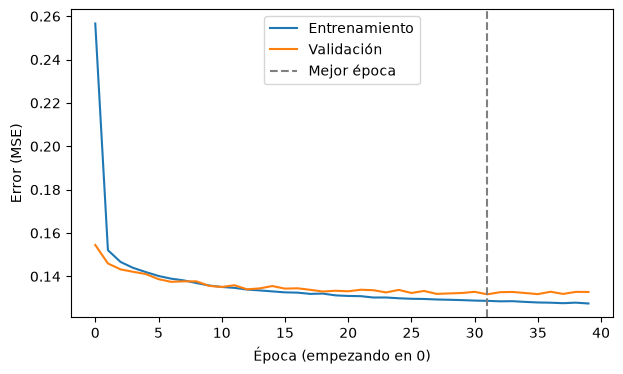

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · entrenamiento,85680.120,156167.146,0.797,0.811
1,Lineal · validación,84918.975,155495.823,0.801,0.815
2,MLP · entrenamiento,69597.103,124739.938,0.871,0.873
3,MLP · validación,71022.859,126184.112,0.869,0.869


In [29]:
def predecir_log_precio(red, X_tensor, media_y, desv_y):
    '''Devuelve el log-precio predicho, ya en su escala original (no estandarizada)'''
    red.eval()
    with torch.no_grad():
        salida = red(X_tensor)          # tensor (N, 1) en escala estandarizada
    salida = salida.numpy()             # lo pasamos a array de NumPy
    salida = salida.reshape(-1)         # (N, 1) -> (N,)
    log_precio = salida * desv_y + media_y   # deshacemos la estandarización
    return log_precio

# Gráfica de la curva de aprendizaje
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(historial_train, label="Entrenamiento")
ax.plot(historial_val, label="Validación")
ax.axvline(mejor_epoca - 1, color="gray", linestyle="--", label="Mejor época")   # la lista empieza en 0
ax.set_xlabel("Época (empezando en 0)")
ax.set_ylabel("Error (MSE)")
ax.legend()
carpeta_figuras = Path("../figuras")
carpeta_figuras.mkdir(exist_ok=True)
fig.savefig(carpeta_figuras / "curva_aprendizaje_mlp.png", dpi=200)
plt.show()

# Resultados del MLP, añadidos a los de la regresión lineal
pred_train = predecir_log_precio(red, X_train_t, media_y, desv_y)
pred_val = predecir_log_precio(red, X_val_t, media_y, desv_y)
resultados.append(evaluar("MLP · entrenamiento", y_train, pred_train))
resultados.append(evaluar("MLP · validación", y_val, pred_val))
pd.DataFrame(resultados).round(3)

## 5. Ubicación: latitud y longitud

Hasta ahora la red solo sabe en qué **ciudad** está la vivienda y a cuántos kilómetros del centro y del metro, pero no **dónde** exactamente. En vivienda la ubicación es lo más importante (un barrio cuesta mucho más que otro de la misma ciudad), así que añadimos la latitud y la longitud que trae el dataset.

La fila de Madrid con latitud 36,76 (un error de coordenadas, a 415 km del centro) ya se eliminó en la limpieza de la sección 2, porque la distancia al centro era mayor de 30 km.

### Latitud y longitud por ciudad

Comprobamos que los valores tienen sentido: dentro de cada ciudad deben variar muy poco (unas centésimas de grado).

In [30]:
df_limpio.groupby("CITY")[["LATITUDE", "LONGITUDE"]].agg(["min", "median", "max"]).round(3)

LATITUDE                 LONGITUDE              
               min  median     max       min median    max
CITY                                                      
Barcelona   41.326  41.398  41.468     2.092  2.167  2.222
Madrid      40.329  40.423  40.521    -3.834 -3.694 -3.541
Valencia    39.438  39.470  39.504    -0.421 -0.378 -0.320

### Mapa de precios

Dibujamos cada vivienda en su posición (longitud en el eje x, latitud en el eje y) y la coloreamos según el log-precio. Usamos una muestra de 20.000 viviendas para que el dibujo sea rápido. Si la ubicación importa, se tienen que ver zonas caras y zonas baratas.

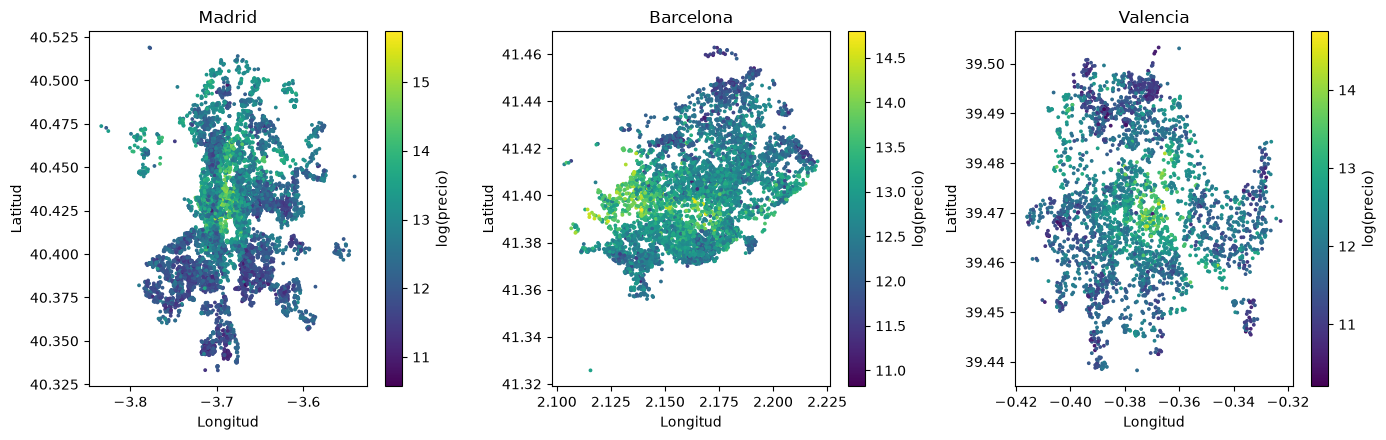

In [31]:
muestra_mapa = df_limpio.sample(20000, random_state=42)

fig, ejes = plt.subplots(1, 3, figsize=(14, 4.5))
for i in range(3):
    ciudad = orden[i]
    datos_ciudad = muestra_mapa[muestra_mapa["CITY"] == ciudad]
    puntos = ejes[i].scatter(datos_ciudad["LONGITUDE"], datos_ciudad["LATITUDE"],
                             c=np.log(datos_ciudad["PRICE"]), s=3, cmap="viridis")
    ejes[i].set_title(ciudad)
    ejes[i].set_xlabel("Longitud")
    ejes[i].set_ylabel("Latitud")
    fig.colorbar(puntos, ax=ejes[i], label="log(precio)")
fig.tight_layout()
fig.savefig(carpeta_figuras / "mapa_precios.png", dpi=200)
plt.show()

### Añadir la latitud y la longitud a las entradas

Hacemos lo mismo que con las demás variables numéricas:

- Estandarizamos con la media y la desviación del **entrenamiento** (`fit` solo con el entrenamiento) y aplicamos a los tres conjuntos.
- Trabajamos con **copias** (`.copy()`) de las tablas anteriores, para no estropear las de la sección 4 y poder comparar con y sin ubicación.
- `df_limpio.loc[Xs_train.index, COORD]` coge las coordenadas de las mismas filas que tiene `Xs_train`: las tablas conservan el número de fila original, así que cuadran.

Ahora cada vivienda tiene 23 entradas en lugar de 21.

In [32]:
COORD = ["LATITUDE", "LONGITUDE"]

# El escalador se ajusta SOLO con el entrenamiento
escalador_coord = StandardScaler().fit(df_limpio.loc[Xs_train.index, COORD])

# Copias de las tablas de la sección 4
Xs_train_geo = Xs_train.copy()
Xs_val_geo = Xs_val.copy()
Xs_test_geo = Xs_test.copy()

# Añadimos las dos columnas nuevas, ya estandarizadas
Xs_train_geo[COORD] = escalador_coord.transform(df_limpio.loc[Xs_train.index, COORD])
Xs_val_geo[COORD] = escalador_coord.transform(df_limpio.loc[Xs_val.index, COORD])
Xs_test_geo[COORD] = escalador_coord.transform(df_limpio.loc[Xs_test.index, COORD])

print("Entradas antes:", Xs_train.shape[1], "| ahora:", Xs_train_geo.shape[1])
print("Medias:", Xs_train_geo[COORD].mean().round(2).to_dict())
print("Desviaciones:", Xs_train_geo[COORD].std().round(2).to_dict())

Entradas antes: 21 | ahora: 23
Medias: {'LATITUDE': 0.0, 'LONGITUDE': 0.0}
Desviaciones: {'LATITUDE': 1.0, 'LONGITUDE': 1.0}


### Regresión lineal con ubicación

Ajustamos otra regresión lineal, ahora con las 23 entradas, y la comparamos con la anterior en validación.

Ojo: una regresión lineal solo puede usar la ubicación de forma muy limitada (una recta en latitud y otra en longitud). Una zona cara rodeada de zonas baratas no se puede representar con rectas. Esperamos una mejora pequeña.

In [33]:
lineal_geo = LinearRegression().fit(Xs_train_geo, y_train)

resultados_ubicacion = []
resultados_ubicacion.append(evaluar("Lineal · sin ubicación", y_val, lineal.predict(Xs_val)))
resultados_ubicacion.append(evaluar("Lineal · con ubicación", y_val, lineal_geo.predict(Xs_val_geo)))
pd.DataFrame(resultados_ubicacion).round(3)

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · sin ubicación,84918.975,155495.823,0.801,0.815
1,Lineal · con ubicación,78942.288,146396.281,0.823,0.842


### MLP con ubicación

Creamos y entrenamos una red nueva con **los mismos hiperparámetros** que la de la sección 4 (64 y 32 neuronas, Adam, lotes de 512, paciencia 8). Lo único que cambia son las entradas: 23 en lugar de 21. Así, cualquier diferencia se debe a la ubicación.

Como siempre, la semilla, la creación y el entrenamiento van en la misma celda, para que cada ejecución empiece desde cero.

In [34]:
# Pasamos las tablas con ubicación a tensores
X_train_geo_t = torch.tensor(Xs_train_geo.values, dtype=torch.float32)
X_val_geo_t = torch.tensor(Xs_val_geo.values, dtype=torch.float32)

torch.manual_seed(42)
red_geo = RedPrecios(X_train_geo_t.shape[1],
                     HIPERPARAMETROS["neuronas_capa1"],
                     HIPERPARAMETROS["neuronas_capa2"])

historial_train_geo, historial_val_geo, mejor_epoca_geo = entrenar_red(
    red_geo, X_train_geo_t, y_train_t, X_val_geo_t, y_val_t,
    HIPERPARAMETROS["tasa_aprendizaje"],
    HIPERPARAMETROS["tam_batch"],
    HIPERPARAMETROS["epocas_max"],
    HIPERPARAMETROS["paciencia"])

print("Mejor época:", mejor_epoca_geo, "| error de validación:", round(min(historial_val_geo), 4))

época 5: entrenamiento 0.1276 | validación 0.1229
época 10: entrenamiento 0.1130 | validación 0.1124
época 15: entrenamiento 0.1093 | validación 0.1096
época 20: entrenamiento 0.1077 | validación 0.1095
época 25: entrenamiento 0.1066 | validación 0.1090
época 30: entrenamiento 0.1057 | validación 0.1071
época 35: entrenamiento 0.1048 | validación 0.1069
Paramos en la época 39: 8 épocas seguidas sin mejorar
Mejor época: 31 | error de validación: 0.1065


### Comparación: con y sin ubicación

Ponemos juntos los cuatro modelos en validación.

In [35]:
pred_val_sin = predecir_log_precio(red, X_val_t, media_y, desv_y)
pred_val_geo = predecir_log_precio(red_geo, X_val_geo_t, media_y, desv_y)

resultados_ubicacion.append(evaluar("MLP · sin ubicación", y_val, pred_val_sin))
resultados_ubicacion.append(evaluar("MLP · con ubicación", y_val, pred_val_geo))
pd.DataFrame(resultados_ubicacion).round(3)

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · sin ubicación,84918.975,155495.823,0.801,0.815
1,Lineal · con ubicación,78942.288,146396.281,0.823,0.842
2,MLP · sin ubicación,71022.859,126184.112,0.869,0.869
3,MLP · con ubicación,65172.315,119753.284,0.882,0.894


## 6. Algoritmo genético para optimizar los hiperparámetros

**Hiperparámetros** son los valores que elegimos nosotros antes de entrenar y que la red no aprende: cuántas neuronas tiene cada capa, la tasa de aprendizaje y el tamaño del lote. Hasta ahora usábamos 64-32 neuronas, lr = 0,001 y lote de 512, que son valores razonables pero elegidos sin probar. Un **algoritmo genético** busca una combinación mejor imitando la evolución:

- **Individuo**: una combinación de hiperparámetros (cada uno es un *gen*). Por ejemplo: 128 neuronas, 32 neuronas, lr 0,003, lote 256.
- **Población**: un grupo de individuos (10).
- **Aptitud** (fitness): lo buena que es una combinación. La medimos entrenando una red con esos hiperparámetros y mirando su **error en validación** (cuanto más bajo, mejor).
- **Selección por torneo**: para elegir un padre, se sacan 3 individuos al azar y gana el de mejor aptitud.
- **Cruce**: un hijo coge cada gen de uno de sus dos padres, al azar.
- **Mutación**: con una pequeña probabilidad, un gen cambia a otro valor al azar. Así aparecen valores nuevos.
- **Elitismo**: el mejor individuo pasa tal cual a la siguiente generación, para no perderlo.
- **Generaciones**: repetimos el ciclo (evaluar, seleccionar, cruzar, mutar) 6 veces.

Dos detalles importantes:
- Para que sea rápido, cada red se entrena como máximo 30 épocas (paciencia 5). Esto favorece a las combinaciones que aprenden deprisa; por eso al final **volvemos a entrenar la mejor con la configuración completa** (hasta 100 épocas, paciencia 8).
- Se usa la misma semilla (42) para entrenar todas las redes, de modo que la comparación sea justa. Guardamos en un diccionario (`memoria`) la aptitud de cada combinación para no entrenarla dos veces si vuelve a salir.

Esta sección tarda varios minutos: se entrenan decenas de redes. Imprime una línea cada vez que evalúa una combinación nueva, para que veas que avanza.

### Definir los genes y los parámetros del algoritmo

`OPCIONES` dice qué valores puede tomar cada gen. El resto son los ajustes del propio algoritmo genético.

In [36]:
import random

# Valores que puede tomar cada hiperparámetro (cada gen)
OPCIONES = {
    "neuronas_capa1": [16, 32, 64, 128, 256],
    "neuronas_capa2": [8, 16, 32, 64, 128],
    "tasa_aprendizaje": [0.0003, 0.001, 0.003, 0.01],
    "tam_batch": [128, 256, 512, 1024],
}
NOMBRES_GENES = ["neuronas_capa1", "neuronas_capa2", "tasa_aprendizaje", "tam_batch"]

# Ajustes del algoritmo genético
TAM_POBLACION = 10
N_GENERACIONES = 6
TAM_TORNEO = 3
PROB_CRUCE = 0.8       # probabilidad de que dos padres se crucen
PROB_MUTACION = 0.2    # probabilidad de que mute CADA gen
EPOCAS_MAX_AG = 30     # épocas máximas al evaluar un individuo (menos que en el entrenamiento final)
PACIENCIA_AG = 5

### Las piezas del algoritmo (funciones)

- `crear_individuo`: un individuo al azar (un valor al azar para cada gen).
- `calcular_aptitud`: entrena una red con los hiperparámetros del individuo y devuelve su mejor error de validación. Si esa combinación ya se evaluó, devuelve el valor guardado.
- `seleccion_torneo`: elige el padre.
- `cruce`: mezcla dos padres en un hijo.
- `mutacion`: cambia genes al azar con una probabilidad pequeña.

`dict(individuo)` crea una **copia** del diccionario. Hace falta para que modificar un hijo no cambie a su padre.

In [37]:
def crear_individuo():
    '''Un individuo es un diccionario con un valor al azar para cada gen'''
    individuo = {}
    for gen in NOMBRES_GENES:
        individuo[gen] = random.choice(OPCIONES[gen])
    return individuo


def calcular_aptitud(individuo):
    '''Entrena una red con los hiperparámetros del individuo y devuelve su error de validación (más bajo = mejor)'''
    clave = (individuo["neuronas_capa1"], individuo["neuronas_capa2"],
             individuo["tasa_aprendizaje"], individuo["tam_batch"])
    if clave in memoria:
        return memoria[clave]

    torch.manual_seed(42)
    red_ag = RedPrecios(X_train_geo_t.shape[1], individuo["neuronas_capa1"], individuo["neuronas_capa2"])
    h_train, h_val, mejor_ep = entrenar_red(red_ag, X_train_geo_t, y_train_t, X_val_geo_t, y_val_t,
                                            individuo["tasa_aprendizaje"], individuo["tam_batch"],
                                            EPOCAS_MAX_AG, PACIENCIA_AG, mostrar=False)
    aptitud = min(h_val)
    memoria[clave] = aptitud
    print("  evaluado:", clave, "-> error de validación:", round(aptitud, 4))
    return aptitud


def seleccion_torneo(poblacion, aptitudes):
    '''Saca TAM_TORNEO individuos al azar y devuelve (una copia de) el mejor'''
    mejor_indice = -1
    for i in range(TAM_TORNEO):
        indice = random.randint(0, len(poblacion) - 1)
        if mejor_indice == -1 or aptitudes[indice] < aptitudes[mejor_indice]:
            mejor_indice = indice
    return dict(poblacion[mejor_indice])


def cruce(padre1, padre2):
    '''Cada gen del hijo viene de uno de los dos padres, elegido al azar'''
    hijo = {}
    for gen in NOMBRES_GENES:
        if random.random() < 0.5:
            hijo[gen] = padre1[gen]
        else:
            hijo[gen] = padre2[gen]
    return hijo


def mutacion(individuo):
    '''Cada gen cambia a un valor al azar con probabilidad PROB_MUTACION'''
    for gen in NOMBRES_GENES:
        if random.random() < PROB_MUTACION:
            individuo[gen] = random.choice(OPCIONES[gen])
    return individuo

### Ejecutar el algoritmo genético

En cada generación:
1. Se calcula la aptitud de todos los individuos.
2. Se guarda el mejor error y el error medio (para dibujar la evolución).
3. Se construye la nueva población: primero el mejor individuo (elitismo) y después hijos hasta completar la población (dos padres por torneo, cruce con probabilidad `PROB_CRUCE` y mutación).

La generación 0 es la población inicial, hecha al azar.

In [38]:
random.seed(42)        # fija el azar del algoritmo genético para que sea repetible
memoria = {}           # aptitud de cada combinación ya evaluada (vacía en cada ejecución)

# Población inicial al azar
poblacion = []
for i in range(TAM_POBLACION):
    poblacion.append(crear_individuo())

historial_mejor = []     # mejor error de cada generación
historial_media = []     # error medio de cada generación
mejor_individuo = None

for generacion in range(N_GENERACIONES + 1):

    # 1) Aptitud de todos los individuos
    aptitudes = []
    for individuo in poblacion:
        aptitudes.append(calcular_aptitud(individuo))

    # 2) Mejor individuo y estadísticas de la generación
    indice_mejor = 0
    for i in range(len(aptitudes)):
        if aptitudes[i] < aptitudes[indice_mejor]:
            indice_mejor = i
    mejor_individuo = dict(poblacion[indice_mejor])
    media = sum(aptitudes) / len(aptitudes)
    historial_mejor.append(aptitudes[indice_mejor])
    historial_media.append(media)
    print(f"Generación {generacion}: mejor error {aptitudes[indice_mejor]:.4f} | media {media:.4f} | mejor: {mejor_individuo}")

    if generacion == N_GENERACIONES:
        break

    # 3) Nueva población
    nueva_poblacion = []
    nueva_poblacion.append(dict(poblacion[indice_mejor]))        # elitismo
    while len(nueva_poblacion) < TAM_POBLACION:
        padre1 = seleccion_torneo(poblacion, aptitudes)
        padre2 = seleccion_torneo(poblacion, aptitudes)
        if random.random() < PROB_CRUCE:
            hijo = cruce(padre1, padre2)
        else:
            hijo = dict(padre1)
        hijo = mutacion(hijo)
        nueva_poblacion.append(hijo)
    poblacion = nueva_poblacion

print()
print("Combinaciones distintas evaluadas:", len(memoria))
print("Mejor individuo:", mejor_individuo)

  evaluado: (16, 8, 0.003, 256) -> error de validación: 0.1134
  evaluado: (32, 16, 0.0003, 128) -> error de validación: 0.1118
  evaluado: (256, 64, 0.0003, 128) -> error de validación: 0.1051
  evaluado: (16, 16, 0.001, 128) -> error de validación: 0.1109
  evaluado: (256, 16, 0.01, 256) -> error de validación: 0.1066
  evaluado: (128, 128, 0.003, 128) -> error de validación: 0.1048
  evaluado: (32, 64, 0.003, 512) -> error de validación: 0.107
  evaluado: (32, 16, 0.003, 128) -> error de validación: 0.1089
  evaluado: (16, 64, 0.0003, 512) -> error de validación: 0.1198
  evaluado: (64, 128, 0.003, 128) -> error de validación: 0.1093
Generación 0: mejor error 0.1048 | media 0.1098 | mejor: {'neuronas_capa1': 128, 'neuronas_capa2': 128, 'tasa_aprendizaje': 0.003, 'tam_batch': 128}
  evaluado: (32, 64, 0.003, 128) -> error de validación: 0.1069
  evaluado: (256, 16, 0.01, 128) -> error de validación: 0.1108
  evaluado: (32, 64, 0.0003, 512) -> error de validación: 0.1128
  evaluado: (

### Evolución del error

La línea del mejor individuo nunca sube (gracias al elitismo). La media de la población debería bajar a medida que los individuos malos se van descartando.

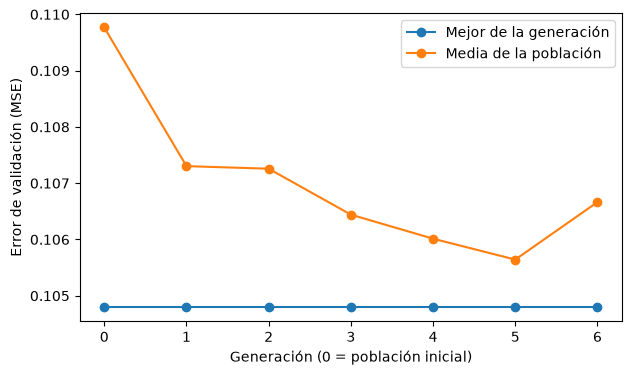

In [39]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(historial_mejor, marker="o", label="Mejor de la generación")
ax.plot(historial_media, marker="o", label="Media de la población")
ax.set_xlabel("Generación (0 = población inicial)")
ax.set_ylabel("Error de validación (MSE)")
ax.legend()
fig.savefig(carpeta_figuras / "evolucion_algoritmo_genetico.png", dpi=200)
plt.show()

### Entrenar con la mejor combinación y comparar con la red anterior

Entrenamos una red con los hiperparámetros del mejor individuo, esta vez con la configuración completa (hasta 100 épocas, paciencia 8), y la comparamos en validación con la red de la sección 5 (64-32 neuronas, lr 0,001, lote 512).

In [40]:
torch.manual_seed(42)
red_ag_final = RedPrecios(X_train_geo_t.shape[1],
                          mejor_individuo["neuronas_capa1"],
                          mejor_individuo["neuronas_capa2"])
h_train_ag, h_val_ag, mejor_epoca_ag = entrenar_red(
    red_ag_final, X_train_geo_t, y_train_t, X_val_geo_t, y_val_t,
    mejor_individuo["tasa_aprendizaje"],
    mejor_individuo["tam_batch"],
    100, 8)

pred_val_ag = predecir_log_precio(red_ag_final, X_val_geo_t, media_y, desv_y)

resultados_ag = []
resultados_ag.append(evaluar("MLP base (64-32, lr 0.001, lote 512)", y_val, pred_val_geo))
resultados_ag.append(evaluar("MLP optimizado por el algoritmo genético", y_val, pred_val_ag))
pd.DataFrame(resultados_ag).round(3)

época 5: entrenamiento 0.1105 | validación 0.1125
época 10: entrenamiento 0.1048 | validación 0.1069
época 15: entrenamiento 0.1006 | validación 0.1073
época 20: entrenamiento 0.0977 | validación 0.1050
época 25: entrenamiento 0.0953 | validación 0.1069
época 30: entrenamiento 0.0936 | validación 0.1125
Paramos en la época 30: 8 épocas seguidas sin mejorar


,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,"MLP base (64-32, lr 0.001, lote 512)",65172.315,119753.284,0.882,0.894
1,MLP optimizado por el algoritmo genético,65114.073,123700.102,0.874,0.896


**Resultado:** el MLP con los hiperparámetros del algoritmo genético (128-128 neuronas, lr 0,003, lote 128) **no mejora de forma clara** a la red base.

- En validación el MAE es casi idéntico (65.114 € frente a 65.172 €, solo 58 € menos) y el R² en log-precio sube muy poco (0,896 frente a 0,894). En cambio, el RMSE y el R² en euros empeoran (123.700 € frente a 119.753 €; 0,874 frente a 0,882): comete algún error grande más en las viviendas caras.
- La salida del entrenamiento lo explica: con una red más grande, una tasa de aprendizaje mayor y lotes más pequeños, el error de entrenamiento sigue bajando (0,094 en la época 30) mientras que el de validación deja de mejorar hacia la época 22 y vuelve a subir (0,1125). Empieza a sobreajustar y la parada temprana lo corta.
- Las mejores combinaciones del algoritmo genético tienen errores muy parecidos entre sí (0,1048-0,1057), del orden de lo que cambiaría con otra semilla. El algoritmo encuentra configuraciones tan buenas como la nuestra, pero no claramente mejores.
- Aun así, llevamos los dos modelos a la evaluación final para ver cómo se comportan en prueba.

## 7. Clasificación por tramos de precio
Hasta ahora hemos **predicho el precio** (regresión). Ahora hacemos una pregunta más sencilla: ¿la vivienda es **barata, media o cara**? Es un problema de **clasificación** con tres clases, y para él usamos los dos modelos que vimos en clase: la **regresión logística** y el **perceptrón multicapa**, este último ya con la salida y la pérdida de clasificación (softmax y entropía cruzada).

### Crear los tres tramos
- Los tramos se definen con los **terciles del precio del entrenamiento**: un tercio de las viviendas es "bajo", otro "medio" y otro "alto". Así las tres clases quedan **equilibradas** y un modelo que acertara al azar tendría un 33 % de accuracy.
- Los dos cortes se calculan **solo con el entrenamiento** (si usáramos validación o prueba, estaríamos filtrando información). Luego se aplican a los tres conjuntos.
- `np.quantile(precios, [1/3, 2/3])` devuelve los dos precios que dejan un tercio de las viviendas por debajo y dos tercios por debajo.
- Etiquetas: 0 = bajo, 1 = medio, 2 = alto.

In [41]:
precios_train = df_limpio.loc[Xs_train.index, "PRICE"]
cortes = np.quantile(precios_train, [1/3, 2/3])
corte_1 = cortes[0]
corte_2 = cortes[1]
print("Corte bajo/medio:", round(corte_1), "€ | corte medio/alto:", round(corte_2), "€")

def asignar_tramo(precio):
    '''Devuelve 0 (bajo), 1 (medio) o 2 (alto) según el precio'''
    if precio < corte_1:
        return 0
    elif precio < corte_2:
        return 1
    else:
        return 2

def crear_etiquetas(indices):
    '''Etiqueta de tramo para cada vivienda cuyo índice nos pasan'''
    precios = df_limpio.loc[indices, "PRICE"]
    etiquetas = []
    for precio in precios:
        etiquetas.append(asignar_tramo(precio))
    return np.array(etiquetas)

tramo_train = crear_etiquetas(Xs_train.index)
tramo_val = crear_etiquetas(Xs_val.index)
tramo_test = crear_etiquetas(Xs_test.index)

NOMBRES_TRAMOS = ["bajo", "medio", "alto"]
for clase in range(3):
    print(NOMBRES_TRAMOS[clase], "-> entrenamiento:", (tramo_train == clase).sum(),
          "| validación:", (tramo_val == clase).sum(), "| prueba:", (tramo_test == clase).sum())

Corte bajo/medio: 189000 € | corte medio/alto: 359000 €
bajo -> entrenamiento: 44113 | validación: 9515 | prueba: 9600
medio -> entrenamiento: 44276 | validación: 9293 | prueba: 9423
alto -> entrenamiento: 44364 | validación: 9677 | prueba: 9470


### Regresión logística multivariable
- La regresión lineal da un número. La regresión logística calcula, para cada clase k, una **puntuación lineal** z_k = w_k · x + b_k (una combinación de las entradas, como en la regresión lineal) y las convierte en **probabilidades** con la **softmax**:  P(clase k) = e^(z_k) / (e^(z_1) + e^(z_2) + e^(z_3)).
- Las tres probabilidades suman 1 y la vivienda se asigna a la clase con **mayor probabilidad**. Se entrena minimizando la **entropía cruzada**, la misma pérdida que vimos en clase para etiquetas one-hot.
- Es un modelo **lineal**: separa las clases con fronteras rectas en el espacio de entradas. Por eso será una buena referencia para comparar con el MLP, que puede dibujar fronteras curvas.
- Usamos las 23 entradas (incluida la ubicación). `max_iter=1000` es el máximo de iteraciones del optimizador interno de sklearn.
- **Accuracy** = proporción de viviendas bien clasificadas.

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

reg_log = LogisticRegression(max_iter=1000)
reg_log.fit(Xs_train_geo, tramo_train)

pred_log_train = reg_log.predict(Xs_train_geo)
pred_log_val = reg_log.predict(Xs_val_geo)

print("Regresión logística · accuracy entrenamiento:", round(accuracy_score(tramo_train, pred_log_train), 3))
print("Regresión logística · accuracy validación:   ", round(accuracy_score(tramo_val, pred_log_val), 3))

Regresión logística · accuracy entrenamiento: 0.782
Regresión logística · accuracy validación:    0.786


### MLP para clasificar
Es la misma red que en la regresión, con **dos cambios**:
1. La capa de salida tiene **3 neuronas** (una por tramo) en vez de 1. Cada una da una puntuación (se llaman *logits*).
2. La pérdida es `nn.CrossEntropyLoss`: aplica la softmax a las tres puntuaciones y calcula la entropía cruzada. **No hay que poner la softmax en la red**, la pérdida ya la incluye. En PyTorch las etiquetas se pasan como números enteros (0, 1, 2), que equivale al one-hot de clase.

El resto no cambia: mismas capas ocultas con ReLU, Adam, mini-batches de 512, parada temprana y los mismos hiperparámetros de la sección 4. En el backpropagation, el error que sale de la capa de salida es ahora **softmax − one-hot**, el equivalente de (ŷ − y) en la regresión; de ahí hacia atrás todo es igual.

La parada temprana vigila ahora el **error de entropía cruzada** en validación (y mostramos también la accuracy).

In [43]:
class RedTramos(nn.Module):
    '''Igual que RedPrecios, pero la capa de salida tiene 3 neuronas (una por tramo)'''
    def __init__(self, n_entradas, n_oculta1, n_oculta2):
        super().__init__()
        self.capa1 = nn.Linear(n_entradas, n_oculta1)
        self.capa2 = nn.Linear(n_oculta1, n_oculta2)
        self.capa_salida = nn.Linear(n_oculta2, 3)
        self.relu = nn.ReLU()

    def forward(self, x):
        z1 = self.capa1(x)
        h1 = self.relu(z1)
        z2 = self.capa2(h1)
        h2 = self.relu(z2)
        return self.capa_salida(h2)    # 3 puntuaciones (logits), sin softmax

def entrenar_clasificador(red, X_train, y_train, X_val, y_val, tasa_aprendizaje, tam_batch, epocas_max, paciencia):
    '''
    Igual que entrenar_red pero con entropía cruzada. y_train e y_val son enteros (0, 1, 2).
    Devuelve: errores de entrenamiento, errores de validación, accuracies de validación y la mejor época.
    '''
    optimizador = torch.optim.Adam(red.parameters(), lr=tasa_aprendizaje)
    funcion_perdida = nn.CrossEntropyLoss()
    n_train = len(X_train)

    historial_train = []
    historial_val = []
    historial_acc_val = []
    mejor_error_val = 1e9
    mejor_epoca = 0
    mejores_pesos = {}
    epocas_sin_mejorar = 0

    for epoca in range(1, epocas_max + 1):
        red.train()
        orden = torch.randperm(n_train)
        suma_errores = 0.0
        for inicio in range(0, n_train, tam_batch):
            indices = orden[inicio:inicio + tam_batch]
            X_batch = X_train[indices]
            y_batch = y_train[indices]

            optimizador.zero_grad()
            salida = red(X_batch)
            error = funcion_perdida(salida, y_batch)
            error.backward()
            optimizador.step()

            suma_errores = suma_errores + error.item() * len(indices)
        error_train = suma_errores / n_train

        red.eval()
        with torch.no_grad():
            salida_val = red(X_val)
            error_val = funcion_perdida(salida_val, y_val).item()
            clases_val = salida_val.argmax(dim=1)          # la clase con mayor puntuación
            acc_val = (clases_val == y_val).float().mean().item()

        historial_train.append(error_train)
        historial_val.append(error_val)
        historial_acc_val.append(acc_val)

        if error_val < mejor_error_val - 1e-5:
            mejor_error_val = error_val
            mejor_epoca = epoca
            epocas_sin_mejorar = 0
            mejores_pesos = {}
            for nombre, tensor in red.state_dict().items():
                mejores_pesos[nombre] = tensor.clone()
        else:
            epocas_sin_mejorar = epocas_sin_mejorar + 1

        if epoca % 5 == 0:
            print(f"época {epoca}: entrenamiento {error_train:.4f} | validación {error_val:.4f} | accuracy val {acc_val:.3f}")

        if epocas_sin_mejorar >= paciencia:
            print(f"Paramos en la época {epoca}: {paciencia} épocas seguidas sin mejorar")
            break

    red.load_state_dict(mejores_pesos)
    return historial_train, historial_val, historial_acc_val, mejor_epoca

In [44]:
# Etiquetas como tensores de enteros (long); las entradas son las mismas con ubicación
tramo_train_t = torch.tensor(tramo_train, dtype=torch.long)
tramo_val_t = torch.tensor(tramo_val, dtype=torch.long)

torch.manual_seed(42)
red_tramos = RedTramos(X_train_geo_t.shape[1],
                       HIPERPARAMETROS["neuronas_capa1"],
                       HIPERPARAMETROS["neuronas_capa2"])

h_train_c, h_val_c, h_acc_c, mejor_epoca_c = entrenar_clasificador(
    red_tramos, X_train_geo_t, tramo_train_t, X_val_geo_t, tramo_val_t,
    HIPERPARAMETROS["tasa_aprendizaje"],
    HIPERPARAMETROS["tam_batch"],
    HIPERPARAMETROS["epocas_max"],
    HIPERPARAMETROS["paciencia"])

print("Mejor época:", mejor_epoca_c, "| error de validación:", round(min(h_val_c), 4))

época 5: entrenamiento 0.4637 | validación 0.4600 | accuracy val 0.800
época 10: entrenamiento 0.4313 | validación 0.4317 | accuracy val 0.812
época 15: entrenamiento 0.4192 | validación 0.4255 | accuracy val 0.815
época 20: entrenamiento 0.4140 | validación 0.4192 | accuracy val 0.819
época 25: entrenamiento 0.4100 | validación 0.4197 | accuracy val 0.819
época 30: entrenamiento 0.4067 | validación 0.4190 | accuracy val 0.821
Paramos en la época 31: 8 épocas seguidas sin mejorar
Mejor época: 23 | error de validación: 0.4152


### Accuracy y matriz de confusión en validación
La **matriz de confusión** tiene una fila por tramo real y una columna por tramo predicho: la diagonal son los aciertos y fuera de la diagonal están los errores. Nos dice no solo cuánto se falla, sino **dónde**. Esperamos que casi todos los errores sean entre tramos vecinos (bajo↔medio, medio↔alto) y muy pocos entre bajo y alto.

Accuracy en validación · regresión logística: 0.786
Accuracy en validación · MLP:                 0.82


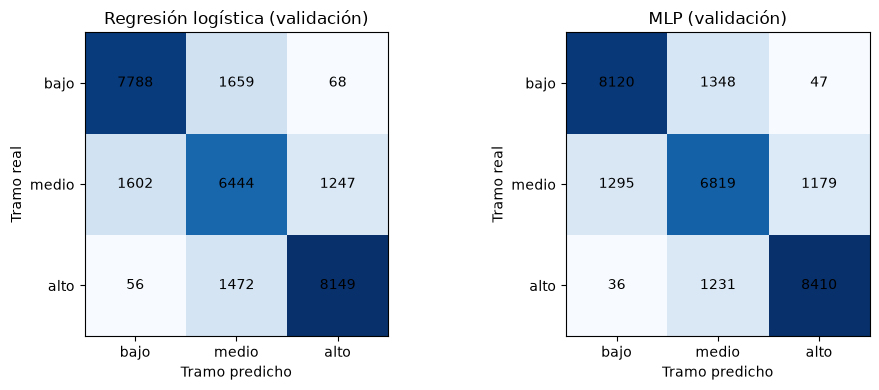

In [45]:
def predecir_tramo(red, X_tensor):
    '''Devuelve el tramo (0, 1 o 2) que predice la red para cada fila'''
    red.eval()
    with torch.no_grad():
        salida = red(X_tensor)
    return salida.argmax(dim=1).numpy()

def dibujar_matriz(ax, tramo_real, tramo_pred, titulo):
    matriz = confusion_matrix(tramo_real, tramo_pred)
    ax.imshow(matriz, cmap="Blues")
    for fila in range(3):
        for columna in range(3):
            ax.text(columna, fila, str(matriz[fila, columna]), ha="center", va="center")
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(NOMBRES_TRAMOS)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(NOMBRES_TRAMOS)
    ax.set_xlabel("Tramo predicho")
    ax.set_ylabel("Tramo real")
    ax.set_title(titulo)

pred_mlp_val_c = predecir_tramo(red_tramos, X_val_geo_t)

print("Accuracy en validación · regresión logística:", round(accuracy_score(tramo_val, pred_log_val), 3))
print("Accuracy en validación · MLP:                ", round(accuracy_score(tramo_val, pred_mlp_val_c), 3))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
dibujar_matriz(ejes[0], tramo_val, pred_log_val, "Regresión logística (validación)")
dibujar_matriz(ejes[1], tramo_val, pred_mlp_val_c, "MLP (validación)")
plt.tight_layout()
fig.savefig(carpeta_figuras / "matrices_confusion_validacion.png", dpi=200)
plt.show()

## 8. Evaluación final en el conjunto de prueba
Hasta aquí hemos comparado todo en **validación**, y la hemos usado para tomar decisiones (parada temprana, hiperparámetros del algoritmo genético). El conjunto de **prueba** no se ha tocado: ahora lo usamos **una sola vez**, con los modelos ya fijados, para estimar cómo funcionarán con viviendas nuevas. No se cambia nada después de mirar estos números.

Modelos de regresión: regresión lineal y MLP (con y sin ubicación) y el MLP optimizado por el algoritmo genético. Modelos de clasificación: regresión logística y MLP.

In [46]:
# Entradas de prueba como tensores
X_test_t = torch.tensor(Xs_test.values, dtype=torch.float32)
X_test_geo_t = torch.tensor(Xs_test_geo.values, dtype=torch.float32)

# Predicciones del log-precio sobre prueba
pred_test = {}
pred_test["Lineal · sin ubicación"] = lineal.predict(Xs_test)
pred_test["Lineal · con ubicación"] = lineal_geo.predict(Xs_test_geo)
pred_test["MLP · sin ubicación"] = predecir_log_precio(red, X_test_t, media_y, desv_y)
pred_test["MLP · con ubicación"] = predecir_log_precio(red_geo, X_test_geo_t, media_y, desv_y)
pred_test["MLP · con ubicación y algoritmo genético"] = predecir_log_precio(red_ag_final, X_test_geo_t, media_y, desv_y)

resultados_test = []
for nombre in pred_test:
    resultados_test.append(evaluar(nombre, y_test, pred_test[nombre]))
tabla_test = pd.DataFrame(resultados_test).round(3)

carpeta_resultados = Path("../resultados")
carpeta_resultados.mkdir(exist_ok=True)
tabla_test.to_csv(carpeta_resultados / "resultados_test_regresion.csv", index=False)
tabla_test

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · sin ubicación,86208.897,161180.827,0.786,0.809
1,Lineal · con ubicación,80103.941,153690.311,0.805,0.839
2,MLP · sin ubicación,71857.576,133564.126,0.853,0.867
3,MLP · con ubicación,65791.357,128051.967,0.865,0.894
4,MLP · con ubicación y algoritmo genético,65056.383,129836.297,0.861,0.896


### ¿Generaliza bien? Validación frente a prueba
Si los números de prueba fueran mucho peores que los de validación, habría sobreajuste a validación. Comparamos el MAE de los dos conjuntos para cada modelo.

In [47]:
pred_val_todos = {}
pred_val_todos["Lineal · sin ubicación"] = lineal.predict(Xs_val)
pred_val_todos["Lineal · con ubicación"] = lineal_geo.predict(Xs_val_geo)
pred_val_todos["MLP · sin ubicación"] = pred_val_sin
pred_val_todos["MLP · con ubicación"] = pred_val_geo
pred_val_todos["MLP · con ubicación y algoritmo genético"] = pred_val_ag

filas = []
for nombre in pred_test:
    mae_val = evaluar(nombre, y_val, pred_val_todos[nombre])["MAE (€)"]
    mae_test = evaluar(nombre, y_test, pred_test[nombre])["MAE (€)"]
    filas.append({"modelo": nombre, "MAE validación (€)": mae_val, "MAE prueba (€)": mae_test,
                  "diferencia (€)": mae_test - mae_val})
pd.DataFrame(filas).round(0)

,modelo,MAE validación (€),MAE prueba (€),diferencia (€)
0,Lineal · sin ubicación,84919.0,86209.0,1290.0
1,Lineal · con ubicación,78942.0,80104.0,1162.0
2,MLP · sin ubicación,71023.0,71858.0,835.0
3,MLP · con ubicación,65172.0,65791.0,619.0
4,MLP · con ubicación y algoritmo genético,65114.0,65056.0,-58.0


### Error del mejor modelo por ciudad y precio predicho frente a real
Como "mejor modelo" tomamos el de menor MAE en validación: el MLP optimizado por el algoritmo genético, aunque está prácticamente empatado con la red base (ver sección 6).

Un solo número de error medio puede esconder que el modelo falle mucho en alguna ciudad. Miramos el MAE por ciudad y, a la derecha, el precio predicho frente al real (si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal).

MAE del mejor modelo por ciudad (prueba):
  Madrid -> 70904 €  ( 14185 viviendas, precio mediano 258000 € )
  Barcelona -> 68114 €  ( 9346 viviendas, precio mediano 325500 € )
  Valencia -> 42580 €  ( 4962 viviendas, precio mediano 150000 € )


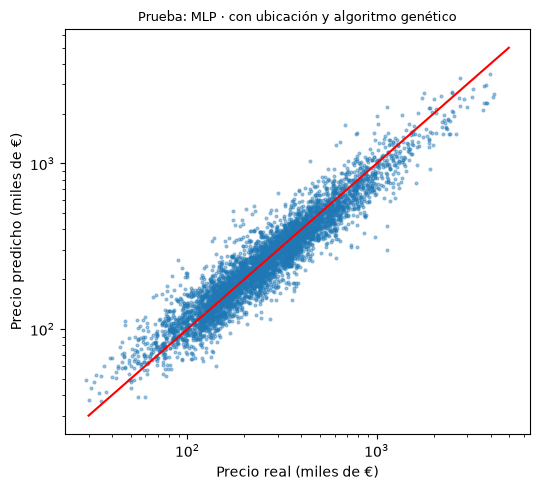

In [48]:
NOMBRE_MEJOR = "MLP · con ubicación y algoritmo genético"
log_pred_mejor = pred_test[NOMBRE_MEJOR]
ciudades_test = df_limpio.loc[Xs_test.index, "CITY"].values

print("MAE del mejor modelo por ciudad (prueba):")
for ciudad in ["Madrid", "Barcelona", "Valencia"]:
    mascara = ciudades_test == ciudad
    real = np.exp(y_test.values[mascara])
    pred = np.exp(log_pred_mejor[mascara])
    print(" ", ciudad, "->", round(mean_absolute_error(real, pred)), "€  (", mascara.sum(), "viviendas, precio mediano", round(np.median(real)), "€ )")

muestra = np.random.RandomState(42).choice(len(y_test), 5000, replace=False)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(np.exp(y_test.values[muestra]) / 1e3, np.exp(log_pred_mejor[muestra]) / 1e3, s=4, alpha=0.4)
ax.plot([30, 5000], [30, 5000], color="red")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Precio real (miles de €)")
ax.set_ylabel("Precio predicho (miles de €)")
ax.set_title("Prueba: " + NOMBRE_MEJOR, fontsize=9)
plt.tight_layout()
fig.savefig(carpeta_figuras / "predicho_vs_real_test.png", dpi=200)
plt.show()

### Clasificación por tramos en prueba

Accuracy en prueba · regresión logística: 0.779
Accuracy en prueba · MLP:                 0.82


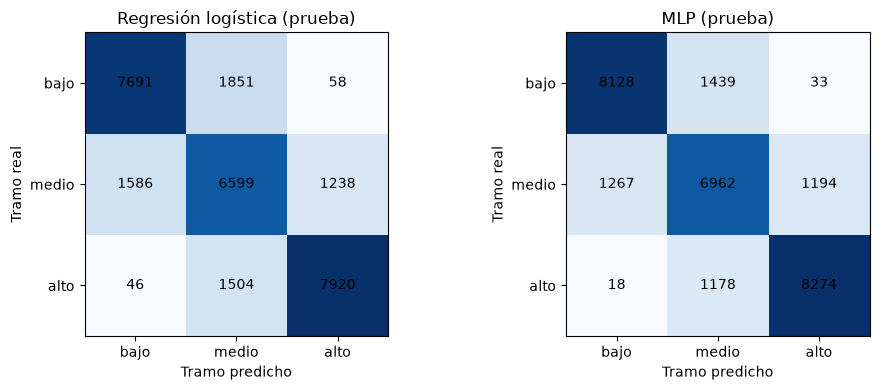

,modelo,accuracy validación,accuracy prueba
0,Regresión logística,0.786,0.779
1,MLP,0.820,0.820


In [49]:
pred_log_test = reg_log.predict(Xs_test_geo)
pred_mlp_test_c = predecir_tramo(red_tramos, X_test_geo_t)

acc_log_test = accuracy_score(tramo_test, pred_log_test)
acc_mlp_test = accuracy_score(tramo_test, pred_mlp_test_c)
print("Accuracy en prueba · regresión logística:", round(acc_log_test, 3))
print("Accuracy en prueba · MLP:                ", round(acc_mlp_test, 3))

tabla_clasif = pd.DataFrame([
    {"modelo": "Regresión logística", "accuracy validación": accuracy_score(tramo_val, pred_log_val), "accuracy prueba": acc_log_test},
    {"modelo": "MLP", "accuracy validación": accuracy_score(tramo_val, pred_mlp_val_c), "accuracy prueba": acc_mlp_test}]).round(3)
tabla_clasif.to_csv(carpeta_resultados / "resultados_test_clasificacion.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
dibujar_matriz(ejes[0], tramo_test, pred_log_test, "Regresión logística (prueba)")
dibujar_matriz(ejes[1], tramo_test, pred_mlp_test_c, "MLP (prueba)")
plt.tight_layout()
fig.savefig(carpeta_figuras / "matrices_confusion_test.png", dpi=200)
plt.show()
tabla_clasif

**Lectura de las matrices:** la diagonal concentra la mayoría de los casos. Los errores están casi todos entre tramos vecinos (bajo↔medio y medio↔alto); confundir "bajo" con "alto" es muy raro. El tramo **medio** es el más difícil porque está en medio y se confunde con los dos lados. El MLP acierta más que la regresión logística porque puede dibujar fronteras curvas, y mantiene la misma accuracy en prueba que en validación.

### Ejemplos: 10 viviendas de prueba
El MAE resume el error en un solo número, pero es más fácil hacerse una idea viendo casos concretos. Cogemos **10 viviendas al azar del conjunto de prueba** (que el modelo nunca ha visto) y ponemos, para cada una, sus características principales, el **precio real** del anuncio y el **precio que predice** el mejor modelo de regresión (MLP con ubicación y algoritmo genético).

- `error (€)` es predicho − real: si es positivo, el modelo se pasa; si es negativo, se queda corto.
- `error (%)` es ese mismo error en proporción al precio real, que permite comparar una vivienda de 150.000 € con una de 1 millón.
- Añadimos también el **tramo** real y el que predice el MLP de clasificación de la sección 7.
- `np.random.RandomState(42)` fija el azar para que salgan siempre las mismas 10 viviendas.

In [50]:
casos = np.random.RandomState(42).choice(len(y_test), 10, replace=False)   # 10 posiciones al azar

filas_ejemplos = []
for i in casos:
    vivienda = df_limpio.loc[Xs_test.index[i]]       # la fila original, con los valores sin estandarizar
    precio_real = np.exp(y_test.values[i])            # volvemos de log a euros
    precio_pred = np.exp(log_pred_mejor[i])
    filas_ejemplos.append({
        "ciudad": vivienda["CITY"],
        "m²": vivienda["CONSTRUCTEDAREA"],
        "habitaciones": vivienda["ROOMNUMBER"],
        "baños": vivienda["BATHNUMBER"],
        "precio real (€)": round(precio_real),
        "precio predicho (€)": round(precio_pred),
        "error (€)": round(precio_pred - precio_real),
        "error (%)": round((precio_pred - precio_real) / precio_real * 100, 1),
        "tramo real": NOMBRES_TRAMOS[tramo_test[i]],
        "tramo predicho": NOMBRES_TRAMOS[pred_mlp_test_c[i]],
    })

tabla_ejemplos = pd.DataFrame(filas_ejemplos)
print("Error absoluto medio de estos 10 casos:", round(tabla_ejemplos["error (€)"].abs().mean()), "€",
      "| MAE en toda la prueba:", round(mean_absolute_error(np.exp(y_test), np.exp(log_pred_mejor))), "€")
tabla_ejemplos

Error absoluto medio de estos 10 casos: 107858 € | MAE en toda la prueba: 65056 €


,ciudad,m²,habitaciones,baños,precio real (€),precio predicho (€),error (€),error (%),tramo real,tramo predicho
0,Madrid,144,3,2,555000,585401,30401,5.5,alto,alto
1,Valencia,129,3,2,137000,213283,76283,55.7,bajo,medio
2,Madrid,110,2,1,447000,348993,-98007,-21.9,alto,alto
3,Barcelona,102,3,2,505000,418427,-86573,-17.1,alto,alto
4,Madrid,70,2,1,164000,174517,10517,6.4,bajo,bajo
5,Barcelona,288,5,3,1095000,1400139,305139,27.9,alto,alto
6,Madrid,215,6,4,946000,859626,-86374,-9.1,alto,alto
7,Barcelona,87,1,1,581000,343881,-237119,-40.8,alto,alto
8,Barcelona,175,4,2,845000,726036,-118964,-14.1,alto,alto
9,Madrid,96,3,2,192000,221201,29201,15.2,medio,medio


## 9. Conclusiones y limitaciones
### Resumen de resultados (prueba)
- **Regresión (precio):** los mejores modelos son los dos MLP con ubicación, con y sin los hiperparámetros del algoritmo genético, que quedan prácticamente empatados: MAE ≈ 65.000 € (65.056 € y 65.791 €), R² ≈ 0,86 en euros y ≈ 0,89-0,90 en log-precio. La regresión lineal con ubicación queda en un MAE ≈ 80.000 € y R² ≈ 0,80.
- **Qué aporta cada cosa:** pasar de lineal a MLP reduce el MAE unos 14.000 € (sin ubicación); añadir latitud y longitud lo reduce otros ≈ 6.000 €; el algoritmo genético solo baja el MAE ≈ 700 € más en prueba (≈ 60 € en validación) y a cambio empeora un poco el RMSE y el R² en euros, así que su aportación no es clara.
- **Generalización:** el error en prueba es parecido al de validación (diferencias de entre -60 y 1.300 € de MAE), así que no hay sobreajuste importante a validación.
- **Por ciudad:** el error absoluto es menor en Valencia (≈ 42.000 €), donde los precios son más bajos, y mayor en Madrid y Barcelona (≈ 68.000-71.000 €).
- **Clasificación por tramos:** la regresión logística acierta ≈ 78 % y el MLP ≈ 82 % (el azar sería 33 %). Casi todos los errores son entre tramos vecinos; confundir una vivienda barata con una cara es muy raro.

### Limitaciones
- **Datos de 2018 y solo tres ciudades.** El modelo no sirve tal cual para otros años u otras ciudades.
- **Faltan variables importantes:** estado de conservación, calidad, orientación, vistas, y el barrio con más detalle que la latitud y la longitud. El error restante se debe en parte a esta información que no tenemos.
- **El precio es el de anuncio**, no el de venta real.
- **El MAE es alto en euros** (≈ 65.000 €) porque los precios van de unas decenas de miles a varios millones; el error es mayor en las viviendas caras.
- **Algoritmo genético con presupuesto pequeño** (población 10, 6 generaciones, 30 combinaciones distintas evaluadas) y con entrenamientos cortos para evaluar cada individuo. La mejora que encuentra es del orden de la variación entre semillas, así que no se puede asegurar que sea la mejor combinación.
- **Una sola partición de los datos y una sola semilla** en los resultados principales (sin validación cruzada).
- **Los tramos de precio dependen de los terciles de entrenamiento**; otros cortes darían otros resultados.

### Líneas futuras
- Probar modelos de árboles (Random Forest, Gradient Boosting), que no hemos visto en clase pero suelen funcionar muy bien con datos tabulares.
- Añadir variables del entorno (renta del barrio, distancia a servicios) y contrastar con índices oficiales de precios (INE).
- Aumentar el presupuesto del algoritmo genético y repetir con varias semillas para medir la variación.
- Predecir el precio por metro cuadrado, que es menos sensible a la superficie.